# Did post-training cause Qwen3's algorithm collapse? A demo of `method.py`

**The question.** Asked to write a shortest-path function, an instruction-tuned LLM writes the same algorithm almost every
time: BFS on an unweighted grid, Dijkstra on a weighted graph. Did **post-training install** this *algorithm-choice
collapse*, or was it **already in the base model**?

**The experiment.** Qwen3-8B-Base vs Qwen3-8B (thinking off), sampled at T = 1, top-p = 1, on two tasks:
**T1**, an unweighted grid path, and **T2**, the shortest path in a weighted directed graph. The core is a 2×2 design,
**weights** (base / instruct) × **prompt format** (chat template / template-free docstring). On top of it:
* *ban* prompts ("Do not use Dijkstra.");
* *steering* arms that subtract the paired instruct-minus-base residual difference (the "sharpening direction") inside the
  instruct model;
* a hash-committed forecast, made from the base model, of which algorithm the instruct model writes once its favourite is
  banned.

Every program extracted from the 4140 samples ran on the hidden tests (47 for T1, 46 for T2) and was labelled (Dijkstra,
Bellman-Ford/SPFA, Floyd-Warshall, …) by a runtime-signature + AST labeller; a blind LLM judge decides when those two
disagree. Diversity is measured by **Hill_cc**, the exponential of the Shannon entropy of the algorithm labels of the
*correct* programs. Hill_cc = 1 means total collapse; Hill_cc = k means k equally likely algorithms.

**Headline results of the full run.**
* The instruct model in chat format is collapsed: T1 BFS 200/200 (Hill_cc 1.00), T2 Dijkstra 193/200 (Hill_cc 1.16).
* The base model under the *same* chat tokens is more diverse (Hill_cc 1.58 and 2.09).
* Pre-registered verdicts: T2 `INSTALLED_BY_POST_TRAINING`, T1 `MIXED`.
* Subtracting the sharpening direction destroys the output instead of restoring diversity.
* A ban prompt raises T2 Hill_cc from 1.16 to 1.99 with no loss in pass rate.

**What `method.py` is.** It is the artifact's single entry point.
* `--all` runs every phase as its own subprocess: vLLM generation, labelling, activation capture and steering with Hugging
  Face, then analysis. This needs a ≥ 24 GB GPU, both 8B models and about 3.5 h.
* `--assemble` rebuilds `runs/samples.jsonl` and `method_out.json` (per-sample rows plus every analysis) from the results on
  disk.

**What this notebook does.**
* Runs the CPU part of `method.py` (the `--assemble` entry point) with its functions unchanged.
* Uses a 100-row subset of the **T2 weighted-shortest-path** dataset: a seeded random sample from every arm, described in
  `mini_demo_data.json → metadata`. It also loads the full-run analysis files that `assemble()` reads.
* Defines the GPU phases (step registry and `run_step`) but does not execute them.
* Ends with plots of the key results: algorithm labels per arm, the Hill-number contrasts behind the verdicts, the steering
  curves, and the per-layer geometry of the sharpening direction.

In [1]:
import subprocess, sys
def _pip(*a): subprocess.check_call([sys.executable, '-m', 'pip', 'install', '-q', *a])

# loguru — NOT pre-installed on Colab, always install (method.py logs with it)
_pip('loguru==0.7.3')

# numpy, pandas, matplotlib — pre-installed on Colab, install locally only (at Colab's exact versions)
if 'google.colab' not in sys.modules:
    _pip('numpy==2.0.2', 'pandas==2.2.2', 'matplotlib==3.10.0')

# torch / vllm / transformers / scipy / openai are only *probed* by lib_versions() (try/except), not needed to run.

In [2]:
from __future__ import annotations

# ---- original import block of method.py ----
import argparse
import json
import os
import platform
import subprocess
import sys
from pathlib import Path

from loguru import logger

# method.py continues with
#   WS = Path(__file__).resolve().parent
#   sys.path.insert(0, str(WS / "src"))
#   from common import (CATALOGUE, DECODING, MB, MI, PRED, RESULTS, RUNS, TASK_NAMES, read_jsonl, setup_logging,
#                       sha256_file, write_jsonl)
# The artifact's src/ folder is not part of this notebook: WS is set in the config cell, and the imported names are
# copied from src/common.py into the "Shared constants and helpers" cell below.

# ---- used by the helpers copied from src/common.py ----
import hashlib
from typing import Iterable

# ---- notebook-only: tables and plots ----
import math
from collections import Counter

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

In [3]:
GITHUB_DATA_URL = "https://raw.githubusercontent.com/ai-inventor-papers/ai-invention-295f8e-prompt-bans-substitute-not-just-subtract/fork/run_5eGZGmskluur/round-1/experiment-5/demo/mini_demo_data.json"
import http.client
import json
import urllib.request
from pathlib import Path

def load_data():
    try:
        with urllib.request.urlopen(GITHUB_DATA_URL, timeout=15) as response:
            return json.loads(response.read().decode())
    # Network errors, timeouts, a placeholder URL, bad JSON, a cut-off response.
    except (OSError, ValueError, http.client.HTTPException) as e:
        print("GitHub data unavailable, using local mini_demo_data.json:", e)
    local = Path("mini_demo_data.json")
    if local.exists(): return json.loads(local.read_text())
    raise FileNotFoundError("Could not load mini_demo_data.json")

In [4]:
data = load_data()
# The GitHub copy is published after this notebook is built and can lag behind it. If the loaded copy lacks the layout
# used below (metadata.support_files), fall back to the mini_demo_data.json shipped next to the notebook.
if "support_files" not in data.get("metadata", {}) and Path("mini_demo_data.json").exists():
    print("GitHub copy of mini_demo_data.json has an older layout, using the local file")
    data = json.loads(Path("mini_demo_data.json").read_text())

md = data["metadata"]
print(f"dataset: {data['datasets'][0]['dataset']}  |  examples (labelled rows): {len(data['datasets'][0]['examples'])}"
      f"  |  support files: {len(md['support_files'])}")
print("selection:", md["selection"])
for fname, v in md["rows_per_file"].items():
    print(f"  {v['n_in_demo']:>3} of {v['n_t2_rows_in_full_run']:>3} T2 rows  {fname}")

GitHub copy of mini_demo_data.json has an older layout, using the local file
dataset: T2_weighted_shortest_path  |  examples (labelled rows): 100  |  support files: 20
selection: seeded random sample (random.Random(20261019)) of T2 rows inside each runs/labelled_*.jsonl file (one arm x condition), spread over prompt paraphrases; no filtering on label or pass/fail
   14 of 300 T2 rows  labelled_base_tf__baseline.jsonl
   18 of 300 T2 rows  labelled_base_chat__baseline.jsonl
   16 of 200 T2 rows  labelled_instruct_chat__baseline.jsonl
   10 of 100 T2 rows  labelled_instruct_tf__baseline.jsonl
    6 of 100 T2 rows  labelled_base_tf__ban.jsonl
   12 of 100 T2 rows  labelled_instruct_chat__ban.jsonl
    2 of 100 T2 rows  labelled_steer__steer_none_c=0.jsonl
    2 of 100 T2 rows  labelled_steer__steer_sharpen_c=0.5.jsonl
    2 of 100 T2 rows  labelled_steer__steer_sharpen_c=1.0.jsonl
    2 of 100 T2 rows  labelled_steer__steer_sharpen_c=1.5.jsonl
    2 of 100 T2 rows  labelled_steer__steer_r

## Configuration

Every knob is in the next cell. The comments give the values of the original full run.

* `CLI_ARGS` — the command-line flags that `main()` in `method.py` parses. `["--assemble"]` is the CPU-only entry point.
  `["--all"]` and `["--step", name]` start the GPU phases, which need the artifact's `src/` scripts and `.venv`, both 8B
  models and a GPU.
* `MAX_ROWS_PER_ARM` — how many rows of each `runs/labelled_*.jsonl` file (one arm × condition) are written back to disk
  and assembled. `None` keeps every example in `mini_demo_data.json`: 100 rows in total, 2–18 per file.
* `WS` — the notebook's stand-in for the artifact folder. In the script it is `Path(__file__).resolve().parent`.
* `CSTAR`, `EXTRA_X`, `EXTRA_XNC` — the steering arguments that `STEPS` passes to `src/steer_hf.py`. Only the GPU phases use
  them.

In [5]:
# ---- which entry point of method.py to run ----------------------------------------------------------------------
CLI_ARGS = ["--assemble"]   # original full pipeline: ["--all"] (GPU phases: ~3.5 h on one 24 GB GPU, ~33 GB of weights)

# ---- demo size ----------------------------------------------------------------------------------------------------
MAX_ROWS_PER_ARM = None     # rows kept per runs/labelled_*.jsonl file; None = all rows of mini_demo_data.json (100)
                            # (tested: 1 -> 18 rows, 4 -> 48 rows, None -> 100 rows; each run < 1 min)
                            # original: every row of every file (4140 programs, both tasks)

# ---- where the notebook rebuilds the artifact folder ---------------------------------------------------------------
WS = Path("demo_artifact").resolve()   # method.py: WS = Path(__file__).resolve().parent

# ---- steering arguments of the GPU phases (used by STEPS, i.e. only with --all / --step) ---------------------------
CSTAR = "t1=0.5,t2=0.5"     # stage R: strength c* of the norm-matched random-direction controls, per task
EXTRA_X = ("sharpenR:1.0:None:10;randomR:1.0:1:10;single18:0.25:None:5;single18:0.5:None:5;"
           "single18:1.0:None:5")   # stage X arms, kind:c:seed:n_paraphrases
EXTRA_XNC = "sharpenR:1.0:None:2"   # validation arm without the 512-token no-code cut-off

## Shared constants and helpers (copied from `src/common.py` and `src/prompts.py`)

`method.py` imports its constants and file helpers from `src/common.py`. The `src/` folder is not part of this notebook, so the
imported names are copied here verbatim, together with the path constants they depend on (now anchored on `WS`). They are:
* the two model ids;
* the task names;
* the algorithm **catalogue** per task, i.e. the labels a program can get (anything else becomes `other`);
* the decoding settings shared by every arm;
* the JSONL, sha256 and logging helpers.

`load_prompts()` comes from `src/prompts.py`.

In [6]:
# ---- from src/common.py (WS comes from the config cell instead of Path(__file__).resolve().parent.parent) ----
SRC = WS / "src"
DATA = WS / "data"
TESTS = DATA / "tests"
REFS = DATA / "refs"
RUNS = WS / "runs"
PRED = WS / "predictions"
ACTS = WS / "activations"
RESULTS = WS / "results"
FIGS = WS / "figures"
LOGS = WS / "logs"
for _d in (DATA, TESTS, REFS, RUNS, PRED, ACTS, RESULTS, FIGS, LOGS):
    _d.mkdir(parents=True, exist_ok=True)

MB = "Qwen/Qwen3-8B-Base"
MI = "Qwen/Qwen3-8B"
TASK_NAMES = {"t1": "T1_unweighted_grid_path", "t2": "T2_weighted_shortest_path"}

T1_LABELS = ["bfs", "dfs", "bidir_bfs", "iddfs", "astar_greedy", "dijkstra_unit"]
T2_LABELS = ["dijkstra", "bellman_ford_spfa", "bidir_dijkstra", "floyd_warshall", "dial"]
CATALOGUE = {"t1": T1_LABELS, "t2": T2_LABELS}

DECODING = {"temperature": 1.0, "top_p": 1.0, "top_k": "disabled", "min_p": 0.0,
            "repetition_penalty": 1.0, "max_tokens": 1024, "thinking": "off"}


def setup_logging(name: str, level: str = "INFO") -> None:
    logger.remove()
    logger.add(sys.stdout, level=level, format="{time:HH:mm:ss}|{level:<7}|{message}")
    logger.add(str(LOGS / f"{name}.log"), rotation="30 MB", level="DEBUG")


def sha256_file(p: Path) -> str:
    h = hashlib.sha256()
    with open(p, "rb") as f:
        for chunk in iter(lambda: f.read(1 << 20), b""):
            h.update(chunk)
    return h.hexdigest()


def read_jsonl(p: Path) -> list[dict]:
    if not p.exists():
        return []
    out = []
    with open(p) as f:
        for line in f:
            line = line.strip()
            if line:
                out.append(json.loads(line))
    return out


def write_jsonl(p: Path, rows: Iterable[dict]) -> None:
    tmp = p.with_suffix(p.suffix + ".tmp")
    with open(tmp, "w") as f:
        for r in rows:
            f.write(json.dumps(r) + "\n")
    tmp.replace(p)


# ---- from src/prompts.py ----
def load_prompts() -> dict:
    return json.loads((DATA / "prompts.json").read_text())

## Rebuild the artifact folder from the loaded data (notebook-only step)

`method.py` reads everything from disk:
* the labelled per-sample rows (`runs/labelled_*.jsonl`);
* the frozen prompts (`data/prompts.json`) and the hidden tests (`data/tests/`);
* the analysis results (`results/*.json`);
* the hash-committed forecast (`predictions/`).

`mini_demo_data.json` holds one dataset, `T2_weighted_shortest_path`. Its 100 examples are labelled rows, each tagged with
the `source_file` it came from. The other files are kept in `metadata.support_files`, keyed by their path inside the
artifact folder. This cell writes everything back under `WS`, so every function below runs **unchanged**.
* `MAX_ROWS_PER_ARM` trims each labelled file.
* The forecast file is stored as raw text, so its sha256 still matches the hash committed before the ban experiment ran.

`results/*.json` hold the analyses of the **full** run (all 4140 samples, both tasks). These are the reference numbers that
`assemble()` copies into `method_out.json → metadata`. The per-sample `datasets` part is built from the demo rows.

In [7]:
rows_by_file = {}
for r in data["datasets"][0]["examples"]:
    r = dict(r)
    rows_by_file.setdefault(r.pop("source_file"), []).append(r)
for rel, rows in rows_by_file.items():          # labelled per-sample rows of one arm x condition
    p = WS / rel
    p.parent.mkdir(parents=True, exist_ok=True)
    write_jsonl(p, rows if MAX_ROWS_PER_ARM is None else rows[:MAX_ROWS_PER_ARM])

for rel, content in data["metadata"]["support_files"].items():
    p = WS / rel
    p.parent.mkdir(parents=True, exist_ok=True)
    # raw text stays byte-exact (predictions/*); parsed JSON is written back as JSON
    p.write_text(content if isinstance(content, str) else json.dumps(content, indent=1))

n_rows = sum(len(read_jsonl(f)) for f in RUNS.glob("labelled_*.jsonl"))
print(f"rebuilt {len(rows_by_file)} labelled files ({n_rows} rows) and {len(data['metadata']['support_files'])} "
      f"support files under {WS.name}/")

rebuilt 18 labelled files (100 rows) and 20 support files under demo_artifact/


## The pipeline: step registry (`STEPS`, `ORDER`)

`method.py --all` walks `ORDER` and runs each step as its own subprocess, so vLLM and Hugging Face never hold the GPU at the
same time.

| step | script | what it does |
|---|---|---|
| `prompts` | `src/prompts.py` | frozen prompt set: 50 neutral lead-ins and 10 ban lead-ins per task, in chat and template-free form, with identical token ids under both tokenizers |
| `tests` | `src/tasks.py` | hidden tests (47 for T1, 46 for T2) |
| `calibrate` | `src/calibrate.py` | per-test time limits from the reference implementations |
| `gate` | `src/labeller_gate.py` | labeller gate on 15 reference implementations and 10 mutants |
| `genA` `genB` `genC` `genAEXT` | `src/gen_vllm.py` | vLLM sampling. A: base model (template-free, chat, template-free + ban). B: instruct model (chat, template-free). C: instruct model under the ban. A_EXT: base arms extended to N = 300 per task. |
| `label` | `src/label_score.py` | extract the code, run the hidden tests, label with the runtime signature and the AST, call the LLM judge where they disagree |
| `acts` | `src/acts_hf.py` | residual states of both models at the read position (the last prompt token), giving the paired instruct−base difference, the "sharpening direction" |
| `predict` | `src/predict_commit.py` | hash-committed forecast of the post-ban algorithm, written before phase C runs |
| `steerS` `steerR` `steerX` `steerXNC` | `src/steer_hf.py` | subtract the direction at strength c: over layers 8–28, at layer 18 only, or at the read position only. Norm-matched random directions serve as controls. |
| `analysis` `report` | `src/analysis.py`, `src/report.py` | Hill numbers, bootstraps, permutation tests, verdicts, BUY / PREDICT rows, figures, summary tables |

The notebook does **not** run these subprocesses: they need the artifact's `src/` scripts and `.venv`, a GPU and both models.
The cell below only defines the registry and prints the plan. `CSTAR`, `EXTRA_X` and `EXTRA_XNC` come from the config cell.

In [8]:
PY = str(WS / ".venv" / "bin" / "python")
STEPS = {
    "prompts": [PY, "src/prompts.py"],
    "tests": [PY, "src/tasks.py"],
    "calibrate": [PY, "src/calibrate.py"],
    "gate": [PY, "src/labeller_gate.py"],
    "genA": [PY, "src/gen_vllm.py", "--phase", "A"],
    "genB": [PY, "src/gen_vllm.py", "--phase", "B"],
    "label": [PY, "src/label_score.py"],
    "acts": None,  # two processes, see run_step
    "predict": [PY, "src/predict_commit.py"],
    "genC": [PY, "src/gen_vllm.py", "--phase", "C"],
    "steerS": [PY, "src/steer_hf.py", "--stage", "S"],
    "steerR": [PY, "src/steer_hf.py", "--stage", "R", "--cstar", CSTAR],
    "steerX": [PY, "src/steer_hf.py", "--stage", "X", "--extra", EXTRA_X],
    "genAEXT": [PY, "src/gen_vllm.py", "--phase", "A_EXT"],
    "steerXNC": [PY, "src/steer_hf.py", "--stage", "X", "--nocutoff", "--extra", EXTRA_XNC],
    "analysis": [PY, "src/analysis.py", "--second_judge"],
    "report": [PY, "src/report.py"],
}
ORDER = ["prompts", "tests", "calibrate", "gate", "genA", "genB", "label", "acts", "predict", "genC", "steerS", "label",
         "steerR", "steerX", "genAEXT", "steerXNC", "label", "analysis", "report"]

# notebook-only: print the plan that `--all` would execute (paths shown relative to the artifact folder)
for i, s in enumerate(ORDER, 1):
    cmd = STEPS[s] or [PY, "src/acts_hf.py", "--model", "base", "&&", "...", "--model", "instruct"]
    print(f"{i:>2}. {s:<9} {' '.join(c.replace(str(WS) + '/', '') for c in cmd)}")

 1. prompts   .venv/bin/python src/prompts.py
 2. tests     .venv/bin/python src/tasks.py
 3. calibrate .venv/bin/python src/calibrate.py
 4. gate      .venv/bin/python src/labeller_gate.py
 5. genA      .venv/bin/python src/gen_vllm.py --phase A
 6. genB      .venv/bin/python src/gen_vllm.py --phase B
 7. label     .venv/bin/python src/label_score.py
 8. acts      .venv/bin/python src/acts_hf.py --model base && ... --model instruct
 9. predict   .venv/bin/python src/predict_commit.py
10. genC      .venv/bin/python src/gen_vllm.py --phase C
11. steerS    .venv/bin/python src/steer_hf.py --stage S
12. label     .venv/bin/python src/label_score.py
13. steerR    .venv/bin/python src/steer_hf.py --stage R --cstar t1=0.5,t2=0.5
14. steerX    .venv/bin/python src/steer_hf.py --stage X --extra sharpenR:1.0:None:10;randomR:1.0:1:10;single18:0.25:None:5;single18:0.5:None:5;single18:1.0:None:5
15. genAEXT   .venv/bin/python src/gen_vllm.py --phase A_EXT
16. steerXNC  .venv/bin/python src/steer_h

### `run_step` — one phase as a subprocess

Every step except `acts` is a single command from `STEPS`, run with the artifact folder as the working directory. `acts`
captures residual states for the base model and then for the instruct model, in two separate processes. The function is
defined here for completeness; with `CLI_ARGS = ["--assemble"]` it is never called.

In [9]:
def run_step(name: str) -> None:
    logger.info(f"=== step {name}")
    if name == "acts":
        for m in ("base", "instruct"):
            subprocess.run([PY, "src/acts_hf.py", "--model", m], cwd=WS, check=True)
        return
    subprocess.run(STEPS[name], cwd=WS, check=True)

## Provenance helpers

These functions record *where and how* the outputs were produced:
* `lib_versions()` and `hardware()` describe the machine that runs `method.py`. Here that is this notebook's runtime; the full
  run used vLLM 0.11.0 and torch 2.8.0 on one NVIDIA L4.
* `gpu_cost()` sums the GPU time recorded in `time_log.json`.
* `clean()` makes the output strict JSON (NaN and inf become `null`).
* `jload()` is a tolerant JSON reader that returns a default when a file is missing.

In [10]:
def lib_versions() -> dict:
    out = {"python": platform.python_version()}
    for mod in ("torch", "vllm", "transformers", "numpy", "scipy", "openai"):
        try:
            out[mod] = __import__(mod).__version__
        except Exception as e:  # noqa: BLE001 - version probe only
            out[mod] = f"unavailable ({type(e).__name__})"
    return out


def hardware() -> dict:
    hw = {"gpu": None, "cpu_quota": None, "ram_limit_gb": None}
    try:
        hw["gpu"] = subprocess.run(["nvidia-smi", "--query-gpu=name,memory.total,driver_version", "--format=csv,noheader"],
                                   capture_output=True, text=True, timeout=20).stdout.strip()
    except (OSError, subprocess.SubprocessError):
        pass
    try:
        q = int(Path("/sys/fs/cgroup/cpu/cpu.cfs_quota_us").read_text())
        p = int(Path("/sys/fs/cgroup/cpu/cpu.cfs_period_us").read_text())
        hw["cpu_quota"] = q / p if q > 0 else None
        hw["ram_limit_gb"] = int(Path("/sys/fs/cgroup/memory/memory.limit_in_bytes").read_text()) / 1e9
    except (OSError, ValueError):
        pass
    return hw


def clean(x):
    """Strict JSON: NaN/inf -> None, tuples -> lists, recursively."""
    import math as _m
    if isinstance(x, float):
        return None if (_m.isnan(x) or _m.isinf(x)) else x
    if isinstance(x, dict):
        return {str(k): clean(v) for k, v in x.items()}
    if isinstance(x, (list, tuple)):
        return [clean(v) for v in x]
    return x


def gpu_cost() -> dict:
    """GPU time from time_log.json: sum of per-phase reported seconds and the wall-clock span of GPU phases."""
    import datetime as _dt
    tl = jload(WS / "time_log.json", []) or []
    secs = sum(float(e.get("seconds", 0) or 0) for e in tl if str(e.get("event", "")).endswith("_end"))
    ts = [_dt.datetime.strptime(e["utc"], "%Y-%m-%dT%H:%M:%SZ") for e in tl
          if any(str(e.get("event", "")).startswith(p) for p in ("gen_", "acts_", "steer_"))]
    span = (max(ts) - min(ts)).total_seconds() if ts else 0.0
    return {"gpu_hours_phase_sum": round(secs / 3600, 2), "gpu_wall_span_hours": round(span / 3600, 2),
            "gpu": "1x NVIDIA L4 23 GB"}


def jload(p: Path, default=None):
    try:
        return json.loads(p.read_text())
    except (OSError, json.JSONDecodeError):
        return default

## From labelled rows to the shared row schema

`label_score.py` writes one JSON row per generated sample (`runs/labelled_*.jsonl`). A row holds:
* the raw model output (`text`) and the extracted program (`code`);
* parse and format flags;
* the hidden-test outcome (`passed`);
* the three labeller opinions (`runtime_label`, `ast_label`, `judge_label`) and the final `label`.

`shared_schema()` projects a row onto the fields shared by every arm; this projection is also published as
`runs/samples.jsonl`. `example_of()` turns a row into one `exp_gen_sol_out` example: the prompt becomes `input`, the raw
generation `output`, the final label and pass flag the `predict_*` fields, and every schema field a `metadata_*` field.

In [11]:
def all_labelled() -> list[dict]:
    rows = []
    for f in sorted(RUNS.glob("labelled_*.jsonl")):
        rows.extend(read_jsonl(f))
    return rows


def shared_schema(r: dict) -> dict:
    return {"task": r["task"], "condition": r["condition"], "paraphrase_id": r["paraphrase_id"], "sample_id": r["sample_id"],
            "model": r["model"], "decoding": r.get("decoding", DECODING), "label": r.get("label"),
            "labeller_source": r.get("labeller_source"), "passed": bool(r.get("passed")), "wall_s": r.get("wall_s"),
            "code_sha256": r.get("code_sha256"), "code": r.get("code"),
            "arm": r["arm"], "template": r["template"], "steer": r.get("steer"), "prompt_id": r["prompt_id"],
            "seed": r.get("seed"), "engine": r.get("engine"), "stage": r.get("stage"), "finish_reason": r.get("finish_reason"),
            "n_tokens": r.get("n_tokens"), "parse_ok": r.get("parse_ok"), "format_ok_loose": r.get("format_ok_loose"),
            "format_ok_strict": r.get("format_ok_strict"), "refusal": r.get("refusal"), "degenerate": r.get("degenerate"),
            "chat_leak": r.get("chat_leak"), "runtime_label": r.get("runtime_label"), "ast_label": r.get("ast_label"),
            "judge_label": r.get("judge_label"), "fail_case": r.get("fail_case"), "error": r.get("error")}


def example_of(r: dict, prompt_text: str) -> dict:
    ex = {"input": prompt_text, "output": r.get("text", ""),
          "predict_algorithm_label": r.get("label") or "unparseable",
          "predict_passes_hidden_tests": "true" if r.get("passed") else "false"}
    for k, v in shared_schema(r).items():
        if k in ("code",):
            ex["metadata_program"] = v
            continue
        ex[f"metadata_{k}"] = v
    return ex

Below is one labelled row, the first instruct-chat sample, projected onto the shared schema (long strings are shortened).
* `labeller_source = runtime+ast` means the runtime-signature label and the AST label agreed, so that label is final.
* The blind LLM judge labels every parseable program, but its label decides only when those two disagree
  (`labeller_source = judge`).
* Unparseable outputs have no label.

In [12]:
_row = next(r for r in all_labelled() if r["arm"] == "instruct_chat" and r["condition"] == "baseline")
for k, v in shared_schema(_row).items():
    s = str(v).replace("\n", " | ")
    print(f"{k:>16}: {s[:100] + ' ...' if len(s) > 100 else s}")

            task: t2
       condition: baseline
   paraphrase_id: 9
       sample_id: 12
           model: Qwen/Qwen3-8B
        decoding: {'temperature': 1.0, 'top_p': 1.0, 'top_k': 'disabled', 'min_p': 0.0, 'repetition_penalty': 1.0, 'ma ...
           label: dijkstra
 labeller_source: runtime+ast
          passed: True
          wall_s: 0.022876067087054253
     code_sha256: 325dff285faa6027ef859247bf5e18a0f7c43f8e94f7ebbd36e1736e0a14a4d2
            code: import heapq |  | def solve(n, edges, s, t): |     if s == t: |         return 0 |     graph = [[] f ...
             arm: instruct_chat
        template: chat
           steer: None
       prompt_id: P9
            seed: 766652957
          engine: vllm
           stage: full
   finish_reason: stop
        n_tokens: 193
        parse_ok: True
 format_ok_loose: True
format_ok_strict: True
         refusal: False
      degenerate: False
       chat_leak: None
   runtime_label: dijkstra
       ast_label: dijkstra
     judge_label: d

## `assemble()` — build `runs/samples.jsonl` and `method_out.json`

This is the CPU-only core of `--assemble`. It works in four steps.
1. Load the frozen prompts and every labelled row, and write all rows in the shared schema to `runs/samples.jsonl`.
2. Look up the exact prompt text of each row (template × task × baseline/ban × paraphrase id) and build one dataset of
   `exp_gen_sol_out` examples per task: `T1_unweighted_grid_path` and `T2_weighted_shortest_path`.
3. Gather every analysis into `metadata`:
   * models, decoding, library versions, hardware and engine settings;
   * deviations, the time log, hidden-test counts, prompt checks, special-token norms and harness calibration;
   * **labeller QA**, the per-**arm** metrics and the **collapse screen** (2×2 contrasts and verdicts);
   * the **sharpening direction** diagnostics, hook unit tests, **steering** results and gap-closed checks;
   * base-model ban obedience, the **BUY / PREDICT** rows and the forecast's hash commitment;
   * priors, sanity checks, costs and the figure list.
4. Write `method_out.json` as strict JSON (`clean()` turns NaN and inf into `null`).

The only change from the script is that `load_prompts` is defined above instead of imported from `src/prompts.py`. The T1
dataset comes out empty in this demo, because only T2 rows are shipped.

In [13]:
def assemble() -> None:
    # from prompts import load_prompts   (notebook: load_prompts is defined in the shared-helpers cell)
    prompts = load_prompts()
    rows = all_labelled()
    write_jsonl(RUNS / "samples.jsonl", [shared_schema(r) for r in rows])
    ptext = {}
    for tmpl in ("chat", "tf"):
        for task in ("t1", "t2"):
            for kind in ("baseline", "ban"):
                for p in prompts[tmpl][task][kind]:
                    ptext[(tmpl, task, kind, p["id"])] = p["text"]
    datasets = []
    for task in ("t1", "t2"):
        ex = []
        for r in rows:
            if r["task"] != task:
                continue
            kind = "baseline" if r["condition"] == "baseline" else "ban"
            ex.append(example_of(r, ptext[(r["template"], task, kind, r["prompt_id"])]))
        datasets.append({"dataset": TASK_NAMES[task], "examples": ex})
    an = jload(RESULTS / "analysis.json", {})
    sd = jload(RESULTS / "sharpening_direction.json", {})
    if sd:
        for t in sd.get("tasks", {}).values():
            t.pop("band_increment_norms", None)
    gen_meta = {ph: jload(RESULTS / f"gen_meta_{ph}.json") for ph in ("A", "B", "C", "A_EXT")}
    pred_file = PRED / "predict_modal_ban.json"
    meta = {
        "method_name": "post-training collapse screen: 2x2 weights-by-format decomposition + sharpening-direction steering + "
                       "hash-committed base-model forecast",
        "description": ("Qwen3-8B-Base vs Qwen3-8B (thinking off) on two path-search tasks (T1 unweighted grid path, T2 weighted "
                        "shortest path). Arms: base template-free, base chat-templated, instruct chat, instruct template-free "
                        "(2x2), modal-ban arms, and HF steering arms that subtract the paired instruct-minus-base residual "
                        "difference (band-incremental over layers 8-28, plus fallbacks). Every program is scored on >=44 hidden "
                        "tests and labelled by a runtime-signature + AST labeller with a blind LLM judge for disagreements."),
        "models": {"base": MB, "instruct": MI}, "decoding": DECODING,
        "library_versions": lib_versions(), "hardware": hardware(), "gen_engine_meta": gen_meta,
        "deviations": jload(RESULTS / "deviations.json", []),
        "time_log": jload(WS / "time_log.json", []),
        "tasks": {t: {"name": TASK_NAMES[t], "catalogue": CATALOGUE[t],
                      "n_hidden_tests": len(jload(WS / "data" / "tests" / f"{t}.json", {}).get("cases", []))} for t in ("t1", "t2")},
        "prompts_sha256": jload(WS / "data" / "prompts.json", {}).get("sha256_all"),
        "prompt_checks": jload(WS / "data" / "prompts.json", {}).get("checks"),
        "special_token_norms": {m: jload(RESULTS / f"special_token_norms_{m}.json") for m in ("base", "instruct")},
        "harness_calibration": jload(RESULTS / "harness_calibration.json"),
        "labeller_qa": an.get("labeller_qa"),
        "arms": an.get("arms"),
        "collapse_screen": an.get("collapse_screen"),
        "sharpening_direction": sd,
        "hook_tests": jload(RESULTS / "hook_tests.json"),
        "steering": an.get("steering"),
        "manipulation_gap_closed": an.get("manipulation"),
        "base_ban_obedience": an.get("base_ban_obedience"),
        "rows": an.get("rows"),
        "predict_commit": {"file": "predictions/predict_modal_ban.json",
                           "sha256_now": sha256_file(pred_file) if pred_file.exists() else None,
                           "hash_log": (PRED / "hash_log.txt").read_text().splitlines() if (PRED / "hash_log.txt").exists() else [],
                           "git_commit": (PRED / "git_commit.txt").read_text().strip() if (PRED / "git_commit.txt").exists() else None,
                           "guard_test": jload(RESULTS / "predict_guard_test.json")},
        "priors": an.get("priors"),
        "analysis_sanity_checks": an.get("sanity"),
        "costs": {"judge": jload(RESULTS / "judge_cost.json"), "gpu": gpu_cost()},
        "figures": an.get("figures"),
        "kept_artifacts": {"activations/": "per-model residual states at R and teacher-forced generated positions, deltas, "
                                           "band steering vectors (kept on the run volume; each file < 100 MB)",
                           "runs/": "raw generations, labelled per-sample rows, caches",
                           "predictions/": "hash-committed forecast + hash log + commit record"},
    }
    out = clean({"metadata": meta, "datasets": datasets})
    (WS / "method_out.json").write_text(json.dumps(out, indent=1, default=str, allow_nan=False))
    logger.info(f"method_out.json written: {sum(len(d['examples']) for d in datasets)} examples")

## `main()` — the command-line entry point

`main()` is unchanged except that `argparse` parses `CLI_ARGS` from the config cell instead of the kernel's own command line.
With `["--assemble"]` it sets up logging (to stdout and `logs/method.log`), switches to the artifact folder and calls
`assemble()`. Afterwards the notebook switches back to its own working directory, so cells can be re-run.

In [14]:
@logger.catch(reraise=True)
def main() -> None:
    ap = argparse.ArgumentParser()
    ap.add_argument("--all", action="store_true")
    ap.add_argument("--assemble", action="store_true")
    ap.add_argument("--step", choices=sorted(STEPS))
    a = ap.parse_args(CLI_ARGS)  # notebook: flags from the config cell instead of the command line
    setup_logging("method")
    os.chdir(WS)
    if a.all:
        for s in ORDER:
            run_step(s)
        assemble()
    elif a.step:
        run_step(a.step)
    if a.assemble:
        assemble()


_cwd = os.getcwd()
main()
os.chdir(_cwd)  # notebook: main() switched into the artifact folder; switch back so re-running cells keeps working

11:25:09|INFO   |method_out.json written: 100 examples


## Inspect the assembled output

`method_out.json` has the shape `{"metadata": {...every analysis...}, "datasets": [T1 examples, T2 examples]}`. The next cell
prints the dataset sizes and a table of the demo examples. It then shows three raw generations:
* a typical instruct-chat answer;
* an answer written under "Do not use Dijkstra";
* what the instruct model emits when the sharpening direction is subtracted.

In [15]:
out = json.loads((WS / "method_out.json").read_text())
meta = out["metadata"]
print(f"method_out.json: {(WS / 'method_out.json').stat().st_size / 1e6:.2f} MB, {len(meta)} metadata keys")
for ds in out["datasets"]:
    print(f"  dataset {ds['dataset']}: {len(ds['examples'])} examples")
print(f"runs/samples.jsonl: {len(read_jsonl(RUNS / 'samples.jsonl'))} rows in the shared schema")
print("hidden tests per task:", {t: v["n_hidden_tests"] for t, v in meta["tasks"].items()})
print("library versions of THIS runtime:", meta["library_versions"])

t2_examples = next(d for d in out["datasets"] if d["dataset"] == TASK_NAMES["t2"])["examples"]
ex = pd.DataFrame(t2_examples)
cols = ["metadata_arm", "metadata_condition", "metadata_prompt_id", "metadata_finish_reason", "metadata_n_tokens",
        "metadata_parse_ok", "predict_algorithm_label", "predict_passes_hidden_tests", "metadata_labeller_source"]
print("\nFirst T2 example of every arm x condition:")
display(ex.groupby(["metadata_arm", "metadata_condition"], sort=False).head(1)[cols]
        .rename(columns=lambda c: c.replace("metadata_", "").replace("predict_", "")).reset_index(drop=True))


def show(sel, title, n_lines=30):
    rows = ex[sel]
    if rows.empty:
        print(f"--- {title}: no such row at this MAX_ROWS_PER_ARM ---\n")
        return
    e = rows.iloc[0]
    lines = [ln[:120] for ln in e["output"].splitlines() if ln.strip()]   # blank lines dropped for display
    print(f"--- {title}\n    [arm={e['metadata_arm']}, condition={e['metadata_condition']}, prompt={e['metadata_prompt_id']}, "
          f"label={e['predict_algorithm_label']}, passes hidden tests={e['predict_passes_hidden_tests']}, "
          f"{e['metadata_n_tokens']} tokens]")
    print("\n".join(lines[:n_lines]) + (f"\n[... {len(lines) - n_lines} more lines]" if len(lines) > n_lines else ""))
    print()


show((ex.metadata_arm == "instruct_chat") & (ex.metadata_condition == "baseline"), "instruct chat, plain prompt")
show((ex.metadata_arm == "instruct_chat") & (ex.metadata_condition != "baseline")
     & (ex.predict_algorithm_label != "dijkstra"), "instruct chat, prompt says 'Do not use Dijkstra' (complied)")
show(ex.metadata_arm == "steer:sharpen:c=1.0", "instruct chat, sharpening direction subtracted over layers 8-28 (c=1.0)",
     n_lines=12)

method_out.json: 0.63 MB, 29 metadata keys
  dataset T1_unweighted_grid_path: 0 examples
  dataset T2_weighted_shortest_path: 100 examples
runs/samples.jsonl: 100 rows in the shared schema
hidden tests per task: {'t1': 47, 't2': 46}
library versions of THIS runtime: {'python': '3.12.14', 'torch': 'unavailable (ModuleNotFoundError)', 'vllm': 'unavailable (ModuleNotFoundError)', 'transformers': 'unavailable (ModuleNotFoundError)', 'numpy': '2.0.2', 'scipy': 'unavailable (ModuleNotFoundError)', 'openai': 'unavailable (ModuleNotFoundError)'}

First T2 example of every arm x condition:


,arm,condition,prompt_id,finish_reason,n_tokens,parse_ok,algorithm_label,passes_hidden_tests,labeller_source
0,base_chat,baseline,P2,stop,585,False,unparseable,false,None
1,base_tf,ban:Dijkstra,B3,stop,3,True,other:unimplemented,false,judge
2,base_tf,baseline,P1,stop,468,True,dijkstra,false,judge
3,instruct_chat,ban:Dijkstra,B5,stop,193,True,dijkstra,true,runtime+ast
4,instruct_chat,baseline,P9,stop,193,True,dijkstra,true,runtime+ast
5,instruct_tf,baseline,P8,stop,220,True,dijkstra,true,runtime+ast
6,steer:none:c=0,baseline,P7,stop,186,True,dijkstra,true,runtime+ast
7,steer:random1,baseline,P4,stop,273,True,dijkstra,false,judge
8,steer:random1_Ronly:c=1.0,baseline,P3,fence,320,True,dijkstra,true,runtime+ast
9,steer:random2,baseline,P9,stop,207,True,bellman_ford_spfa,true,judge


--- instruct chat, plain prompt
    [arm=instruct_chat, condition=baseline, prompt=P9, label=dijkstra, passes hidden tests=true, 193 tokens]
```python
import heapq
def solve(n, edges, s, t):
    if s == t:
        return 0
    # Build adjacency list
    graph = [[] for _ in range(n)]
    for u, v, w in edges:
        graph[u].append((v, w))
    # Dijkstra's algorithm
    dist = [float('inf')] * n
    dist[s] = 0
    priority_queue = [(0, s)]
    while priority_queue:
        current_dist, u = heapq.heappop(priority_queue)
        if current_dist > dist[u]:
            continue
        for v, weight in graph[u]:
            if dist[v] > dist[u] + weight:
                dist[v] = dist[u] + weight
                heapq.heappush(priority_queue, (dist[v], v))
    return dist[t] if dist[t] != float('inf') else -1
```

--- instruct chat, prompt says 'Do not use Dijkstra' (complied)
    [arm=instruct_chat, condition=ban:Dijkstra, prompt=B3, label=bellman_ford_spfa, passes hidden tests=true, 2

## Results

All **statistics come from the full run** (`metadata`, 4140 programs). Where it makes sense, the demo rows are shown next to
them. With 2–18 rows per arm they illustrate the full-run pattern, but they cannot reproduce its confidence intervals.

A program is **correct** when it parses, gets an algorithm label and passes every hidden test. The first view is a table of
every T2 arm, comparing the demo rows with the full run: rows, pass rate, the algorithms of the correct programs, the modal
algorithm and Hill_cc. The four views after it each have their own short introduction.

In [16]:
# Hill number of order 1 and label normalisation, copied from src/stats_utils.py
def norm_label(lab: str | None, cats: list[str]) -> str | None:
    if lab is None:
        return None
    return lab if lab in cats else "other"


def hill(counts: np.ndarray) -> float:
    n = counts.sum()
    if n <= 0:
        return float("nan")
    p = counts[counts > 0] / n
    return float(math.exp(-(p * np.log(p)).sum()))


# notebook-only helpers shared by the result views
VLLM_ARMS = ["base_tf", "base_chat", "instruct_tf", "instruct_chat", "base_tf_ban", "instruct_chat_ban"]
STEER_ARMS = ["steer:none:c=0", "steer:sharpen:c=0.5", "steer:sharpen:c=1.0", "steer:sharpen:c=1.5",
              "steer:single18:c=0.25", "steer:single18:c=0.5", "steer:single18:c=1.0", "steer:sharpen_Ronly:c=1.0",
              "steer:sharpen_Ronly:c=1.0+nocutoff", "steer:random1", "steer:random2", "steer:random1_Ronly:c=1.0"]
TASK_COLOR = {"t1": "tab:blue", "t2": "tab:orange"}


def arm_key(e: dict) -> str:
    """Arm name used in metadata['arms']: vLLM arms get '_ban' under the ban prompt, steering arms keep their name."""
    arm, cond = e["metadata_arm"], e["metadata_condition"]
    return arm if (arm.startswith("steer:") or cond == "baseline") else arm + "_ban"


def is_correct(e: dict) -> bool:
    return bool(e["metadata_parse_ok"] and e["metadata_label"] is not None and e["metadata_passed"])


def fmt_ci(ci: dict | None) -> str:
    if not ci or ci.get("est") is None:
        return "-"
    return f"{ci['est']:.2f}" + (f" [{ci['lo']:.2f}, {ci['hi']:.2f}]" if ci.get("lo") is not None else "")


demo = {}
for e in t2_examples:
    demo.setdefault(arm_key(e), []).append(e)

T2_CATS = CATALOGUE["t2"] + ["other"]
table = []
for k in VLLM_ARMS + STEER_ARMS:
    exs, full = demo.get(k, []), meta["arms"].get(f"{k}|t2", {})
    cc = Counter(norm_label(e["metadata_label"], CATALOGUE["t2"]) for e in exs if is_correct(e))
    table.append({
        "arm": k,
        "demo rows": len(exs),
        "demo passed": sum(e["metadata_passed"] for e in exs),
        "demo correct programs": ", ".join(f"{lab} {n}" for lab, n in cc.most_common()) or "-",
        "demo Hill_cc": hill(np.array([cc[c] for c in T2_CATS])) if cc else float("nan"),
        "full N": full.get("N"),
        "full parse rate": full.get("parse_rate"),
        "full pass rate": full["pass_rate"][0] if full.get("pass_rate") else float("nan"),
        "full modal (share of correct)": (f"{full['modal_correct']} ({full['modal_share_correct'][0]:.0%})"
                                          if full.get("modal_correct") else "-"),
        "full Hill_cc [95% CI]": fmt_ci(full.get("hill_cc_ci")),
    })
pd.set_option("display.max_colwidth", 80)
print("T2 weighted shortest path: demo rows vs full run")
display(pd.DataFrame(table).set_index("arm").round(2))

T2 weighted shortest path: demo rows vs full run


,demo rows,demo passed,demo correct programs,demo Hill_cc,full N,full parse rate,full pass rate,full modal (share of correct),full Hill_cc [95% CI]
arm,,,,,,,,,
base_tf,14,1,bellman_ford_spfa 1,1.00,300,0.97,0.08,bellman_ford_spfa (64%),"2.18 [1.00, 2.73]"
base_chat,18,5,"bellman_ford_spfa 2, dijkstra 2, other 1",2.87,300,0.66,0.30,dijkstra (70%),"2.09 [1.63, 2.54]"
instruct_tf,10,8,"dijkstra 6, bellman_ford_spfa 2",1.75,100,0.89,0.72,dijkstra (79%),"1.93 [1.41, 2.37]"
instruct_chat,16,16,dijkstra 16,1.00,200,1.00,1.00,dijkstra (96%),"1.16 [1.03, 1.31]"
base_tf_ban,6,0,-,NaN,100,0.98,0.08,dijkstra (50%),"2.00 [1.00, 2.00]"
instruct_chat_ban,12,12,"dijkstra 8, bellman_ford_spfa 4",1.89,100,1.00,1.00,dijkstra (54%),"1.99 [1.65, 2.00]"
steer:none:c=0,2,2,dijkstra 2,1.00,100,1.00,1.00,dijkstra (100%),"1.00 [1.00, 1.00]"
steer:sharpen:c=0.5,2,0,-,NaN,100,0.00,0.00,-,-
steer:sharpen:c=1.0,2,0,-,NaN,100,0.00,0.00,-,-


### Which algorithm does each arm write?

**(a, b)** In the full run, each bar shows the label shares among the correct programs of the six vLLM arms, for each task.
Above each bar, `n` is the number of correct programs and `H` is Hill_cc.
* Moving from base chat to instruct chat (same tokens, different weights), the modal algorithm takes over: BFS 86 % → 100 %
  on T1, Dijkstra 70 % → 96.5 % on T2.
* Under the ban prompt, the instruct model's second choice appears: DFS on T1, Bellman-Ford on T2. The banned algorithm
  still accounts for 57 of 70 correct programs on T1 and 54 of 100 on T2.

**(c)** Every demo row, one bar per arm (left of the dotted line: vLLM arms; right: steering arms).
* Solid segments are programs that pass every hidden test; hatched segments fail at least one.
* Light grey marks outputs from which no program could be extracted.
* All three band-steering strengths of the sharpening direction (c = 0.5 / 1.0 / 1.5) produce only unparseable text.

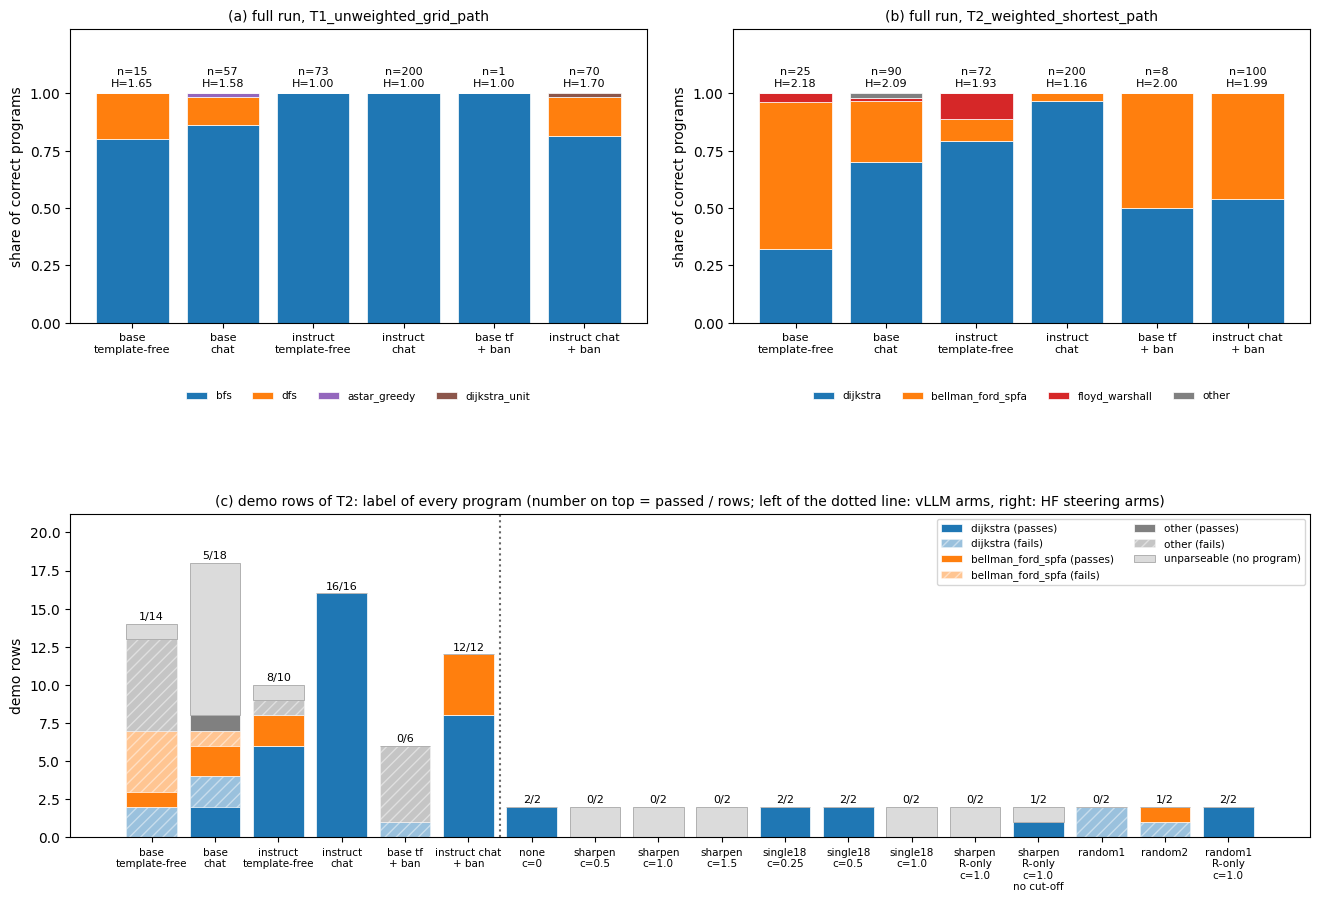

In [17]:
def label_color(task: str, lab: str):
    cats = CATALOGUE[task]
    if lab in cats:
        return plt.cm.tab10(cats.index(lab))
    return "0.5" if lab == "other" else "0.86"   # other = grey, unparseable = light grey


def short(k: str) -> str:
    names = {"base_tf": "base\ntemplate-free", "base_chat": "base\nchat", "instruct_tf": "instruct\ntemplate-free",
             "instruct_chat": "instruct\nchat", "base_tf_ban": "base tf\n+ ban", "instruct_chat_ban": "instruct chat\n+ ban"}
    if k in names:
        return names[k]
    return (k.replace("steer:", "").replace("_Ronly", "\nR-only").replace("+nocutoff", "\nno cut-off")
             .replace(":c=", "\nc="))


fig = plt.figure(figsize=(16, 10.5))
gs = fig.add_gridspec(2, 2, height_ratios=[1, 1.1], hspace=0.62, wspace=0.15)

# (a, b) full run: label shares of the correct programs per vLLM arm
for j, task in enumerate(("t1", "t2")):
    ax = fig.add_subplot(gs[0, j])
    cats = CATALOGUE[task] + ["other"]
    bottom = np.zeros(len(VLLM_ARMS))
    for lab in cats:
        share = []
        for k in VLLM_ARMS:
            cnt = meta["arms"][f"{k}|{task}"]["label_counts_correct"]
            n = sum(cnt.values())
            share.append(cnt.get(lab, 0) / n if n else 0.0)
        share = np.array(share)
        if share.sum():
            ax.bar(range(len(VLLM_ARMS)), share, bottom=bottom, color=label_color(task, lab), label=lab,
                   edgecolor="white", lw=0.5)
        bottom += share
    for i, k in enumerate(VLLM_ARMS):
        a = meta["arms"][f"{k}|{task}"]
        h = f"\nH={a['hill_cc']:.2f}" if a.get("hill_cc") is not None else ""
        ax.text(i, 1.02, f"n={a['n_correct_labelled']}{h}", ha="center", va="bottom", fontsize=8)
    ax.set_xticks(range(len(VLLM_ARMS)), [short(k) for k in VLLM_ARMS], fontsize=8)
    ax.set_ylim(0, 1.28)
    ax.set_yticks([0, 0.25, 0.5, 0.75, 1.0])
    ax.set_ylabel("share of correct programs")
    ax.set_title(f"({'ab'[j]}) full run, {TASK_NAMES[task]}", fontsize=10)
    ax.legend(fontsize=7.5, loc="upper center", bbox_to_anchor=(0.5, -0.2), ncol=4, frameon=False)

# (c) demo rows (T2): label of every program; solid = passes all hidden tests, hatched = fails one
ax = fig.add_subplot(gs[1, :])
arms_c = [k for k in VLLM_ARMS + STEER_ARMS if k in demo]
bottom = np.zeros(len(arms_c))
for lab in T2_CATS:
    for passed in (True, False):
        h = np.array([sum(1 for e in demo[k] if e["metadata_parse_ok"] and e["metadata_label"] is not None
                          and norm_label(e["metadata_label"], CATALOGUE["t2"]) == lab
                          and bool(e["metadata_passed"]) == passed) for k in arms_c])
        if h.sum():
            ax.bar(range(len(arms_c)), h, bottom=bottom, color=label_color("t2", lab), alpha=1.0 if passed else 0.45,
                   hatch=None if passed else "///", edgecolor="white", lw=0.5,
                   label=f"{lab} ({'passes' if passed else 'fails'})")
        bottom += h
h = np.array([sum(1 for e in demo[k] if not (e["metadata_parse_ok"] and e["metadata_label"] is not None)) for k in arms_c])
ax.bar(range(len(arms_c)), h, bottom=bottom, color=label_color("t2", "unparseable"), edgecolor="0.6", lw=0.5,
       label="unparseable (no program)")
bottom += h
for i, k in enumerate(arms_c):
    ax.text(i, bottom[i] + 0.15, f"{sum(bool(e['metadata_passed']) for e in demo[k])}/{len(demo[k])}", ha="center",
            va="bottom", fontsize=8)
ax.axvline(sum(k in demo for k in VLLM_ARMS) - 0.5, color="0.4", ls=":")
ax.set_xticks(range(len(arms_c)), [short(k) for k in arms_c], fontsize=7.5)
ax.set_ylim(0, bottom.max() * 1.15 + 0.5)
ax.set_ylabel("demo rows")
ax.set_title("(c) demo rows of T2: label of every program (number on top = passed / rows; left of the dotted line: "
             "vLLM arms, right: HF steering arms)", fontsize=10)
ax.legend(fontsize=7.5, ncol=2, loc="upper right")
plt.show()

### Is the collapse installed by post-training?

**(a)** Hill_cc per arm, with 95 % paraphrase-cluster bootstrap CIs (2000 resamples over the 10 prompt paraphrases).

**(b)** The 2×2 contrasts. The key one is **D_weights** = Hill_cc(instruct chat) − Hill_cc(base chat): identical prompt
tokens, only the weights differ. **D_format** = Hill_cc(base chat) − Hill_cc(base template-free) isolates the prompt format
inside the base model.

The pre-registered rules, in order:
* **`INSTALLED_BY_POST_TRAINING`** — base chat − instruct chat ≥ 0.5 with a CI above 0, **and** the instruct modal
  algorithm's share rises by ≥ 15 pp from base chat to instruct chat.
* **`INSTALLED_BY_FORMAT`** — the same test applied to base template-free vs base chat.
* **`ALREADY_IN_BASE`** — base template-free has the same mode as instruct chat, and the upper CI bound of its Hill_cc lead
  over instruct chat is below 0.5.
* **`MIXED`** — none of the above.

The table below the plot prints the numbers each verdict rests on.

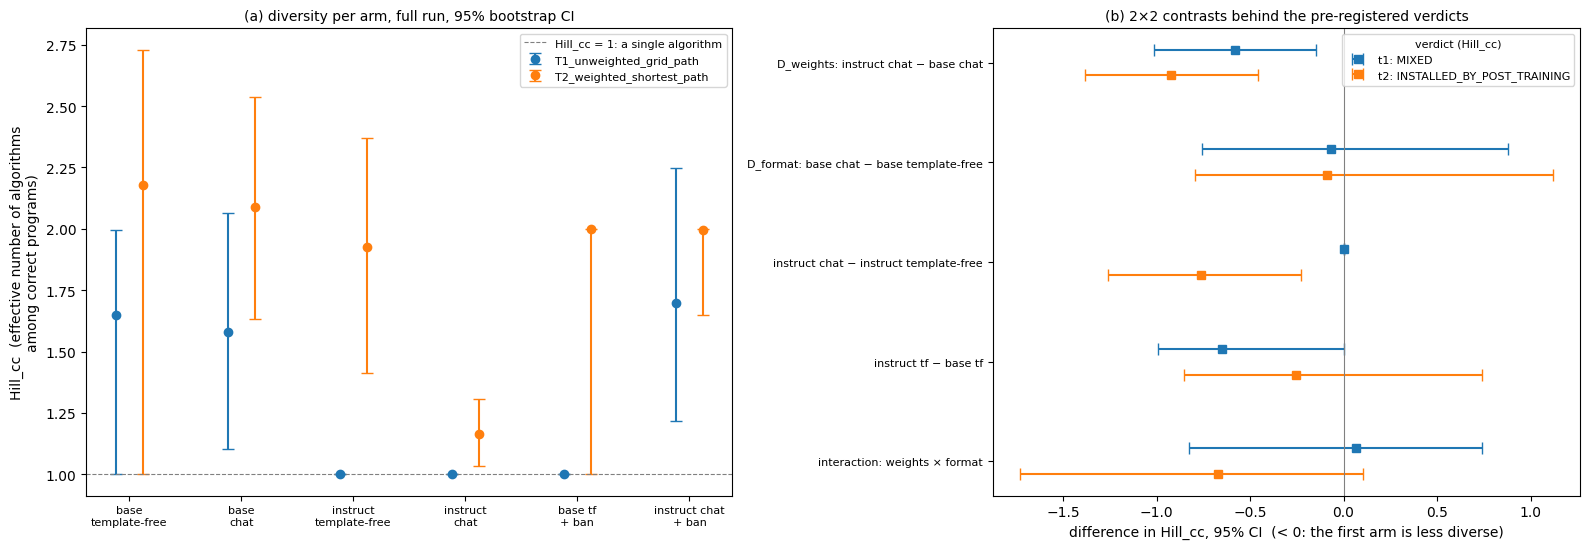

,verdict (Hill_cc),verdict (Hill_all),D_weights_cc [95% CI],instruct modal,its share: instruct chat,its share: base chat,gap (bar 15 pp),base template-free modal
task,,,,,,,,
T1_unweighted_grid_path,MIXED,INSTALLED_BY_POST_TRAINING,"-0.58 [-1.01, -0.15]",bfs,100.0%,86.0%,14.0 pp,bfs
T2_weighted_shortest_path,INSTALLED_BY_POST_TRAINING,INSTALLED_BY_POST_TRAINING,"-0.93 [-1.38, -0.46]",dijkstra,96.5%,70.0%,26.5 pp,bellman_ford_spfa


Alternate 'post-training installed the collapse' passes the screen: Hill_cc True, Hill_all True


In [18]:
cs = meta["collapse_screen"]
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(16, 5.6), gridspec_kw={"width_ratios": [1.1, 1]})

# (a) Hill_cc with 95% bootstrap CI per arm
x = np.arange(len(VLLM_ARMS))
for dx, task in ((-0.12, "t1"), (0.12, "t2")):
    est, lo, hi = [], [], []
    for k in VLLM_ARMS:
        ci = meta["arms"][f"{k}|{task}"].get("hill_cc_ci") or {}
        est.append(np.nan if ci.get("est") is None else ci["est"])
        lo.append(np.nan if ci.get("lo") is None else ci["lo"])
        hi.append(np.nan if ci.get("hi") is None else ci["hi"])
    est, lo, hi = map(np.array, (est, lo, hi))
    yerr = np.nan_to_num(np.vstack([est - lo, hi - est]))
    ax1.errorbar(x + dx, est, yerr=yerr, fmt="o", color=TASK_COLOR[task], capsize=4, label=TASK_NAMES[task])
ax1.axhline(1, color="0.5", ls="--", lw=0.8, label="Hill_cc = 1: a single algorithm")
ax1.set_xticks(x, [short(k) for k in VLLM_ARMS], fontsize=8)
ax1.set_ylabel("Hill_cc  (effective number of algorithms\namong correct programs)")
ax1.set_title("(a) diversity per arm, full run, 95% bootstrap CI", fontsize=10)
ax1.legend(fontsize=8, loc="upper right")

# (b) the 2x2 contrasts behind the verdicts
contrasts = [("D_weights_cc", "D_weights: instruct chat − base chat"),
             ("D_format_cc", "D_format: base chat − base template-free"),
             ("D_format_instruct_cc", "instruct chat − instruct template-free"),
             ("D_weights_tf_cc", "instruct tf − base tf"),
             ("interaction_cc", "interaction: weights × format")]
for dy, task in ((-0.13, "t1"), (0.13, "t2")):
    for i, (key, _) in enumerate(contrasts):
        d = cs[task].get(key) or {}
        if d.get("est") is None:
            continue
        lo_ = d["lo"] if d.get("lo") is not None else d["est"]
        hi_ = d["hi"] if d.get("hi") is not None else d["est"]
        ax2.errorbar(d["est"], i + dy, xerr=[[d["est"] - lo_], [hi_ - d["est"]]], fmt="s", color=TASK_COLOR[task],
                     capsize=4, label=f"{task}: {cs[task]['verdict_cc']['verdict']}" if i == 0 else None)
ax2.axvline(0, color="0.5", lw=0.8)
ax2.set_yticks(range(len(contrasts)), [c[1] for c in contrasts], fontsize=8)
ax2.invert_yaxis()
ax2.set_xlabel("difference in Hill_cc, 95% CI  (< 0: the first arm is less diverse)")
ax2.set_title("(b) 2×2 contrasts behind the pre-registered verdicts", fontsize=10)
ax2.legend(fontsize=8, title="verdict (Hill_cc)", title_fontsize=8, loc="upper right")
plt.tight_layout()
plt.show()

verdicts = []
for task in ("t1", "t2"):
    v, dw = cs[task]["verdict_cc"], cs[task]["D_weights_cc"]
    verdicts.append({"task": TASK_NAMES[task], "verdict (Hill_cc)": v["verdict"],
                     "verdict (Hill_all)": cs[task]["verdict_all"]["verdict"],
                     "D_weights_cc [95% CI]": fmt_ci(dw),
                     "instruct modal": v["instruct_modal"],
                     "its share: instruct chat": f"{v['instruct_modal_share']:.1%}",
                     "its share: base chat": f"{v['base_chat_share_of_instruct_modal']:.1%}",
                     "gap (bar 15 pp)": f"{v['modal_share_gap_pp_weights']:.1f} pp",
                     "base template-free modal": v["base_tf_modal"]})
display(pd.DataFrame(verdicts).set_index("task"))
print("Alternate 'post-training installed the collapse' passes the screen:",
      f"Hill_cc {cs['alternate_passes_screen_cc']}, Hill_all {cs['alternate_passes_screen_all']}")

### Can steering undo it? Activation geometry of the sharpening direction

The **sharpening direction** at layer L is δ_L = mean over 50 paired prompts of (h_instruct − h_base). It is read at the last
prompt token, where both models see identical tokens. Steering subtracts c·δ from the instruct model's residual stream in
one of three ways:
* incrementally over layers 8–28 ("band");
* at layer 18 only;
* at the read position only ("R-only").

Norm-matched random directions serve as controls.

**Top row:** parse rate and pass rate against c, and how far each arm moves the instruct states toward the base states.
"Gap closed" is 1 − ‖mean h_steered − mean h_B‖ / ‖mean h_I − mean h_B‖, measured at layers 8, 18 and 28 (1 = the base
states are reached).
* At layer 8, the band subtraction does exactly what it should. c = 1 closes the gap, c = 0.5 closes half of it, and c = 1.5
  overshoots by half.
* Downstream layers *amplify* the change, so the states shoot past the base states. At c = 1 the gap closed is ≤ 0.08 at
  layers 18 and 28 (on both tasks), and at c = 1.5 it is negative.
* The answer format collapses: 0 % parseable at every band strength.

**Bottom row:** per-layer geometry of δ (shaded = steering band).
* δ is very stable: split-half cosine ≥ 0.997.
* It is large: ‖δ‖ / ‖mean h_B‖ is 0.8–1.2 inside the band.
* It is shared across tasks: cos(δ_T1, δ_T2) is 0.84–0.93 inside the band.
* It is only weakly aligned with the instruct−base difference measured on generated tokens (cos ≈ 0.15–0.4 inside the band).

The logit lens printed below the plot shows what subtracting δ at layer 28 does. It suppresses the instruct model's
answer-format tokens (```` ``` ````, "here"). It promotes raw-code tokens (`def`, `class`) on T1 and chat/prompt tokens on
T2. δ encodes the *answer format*, not the algorithm choice.

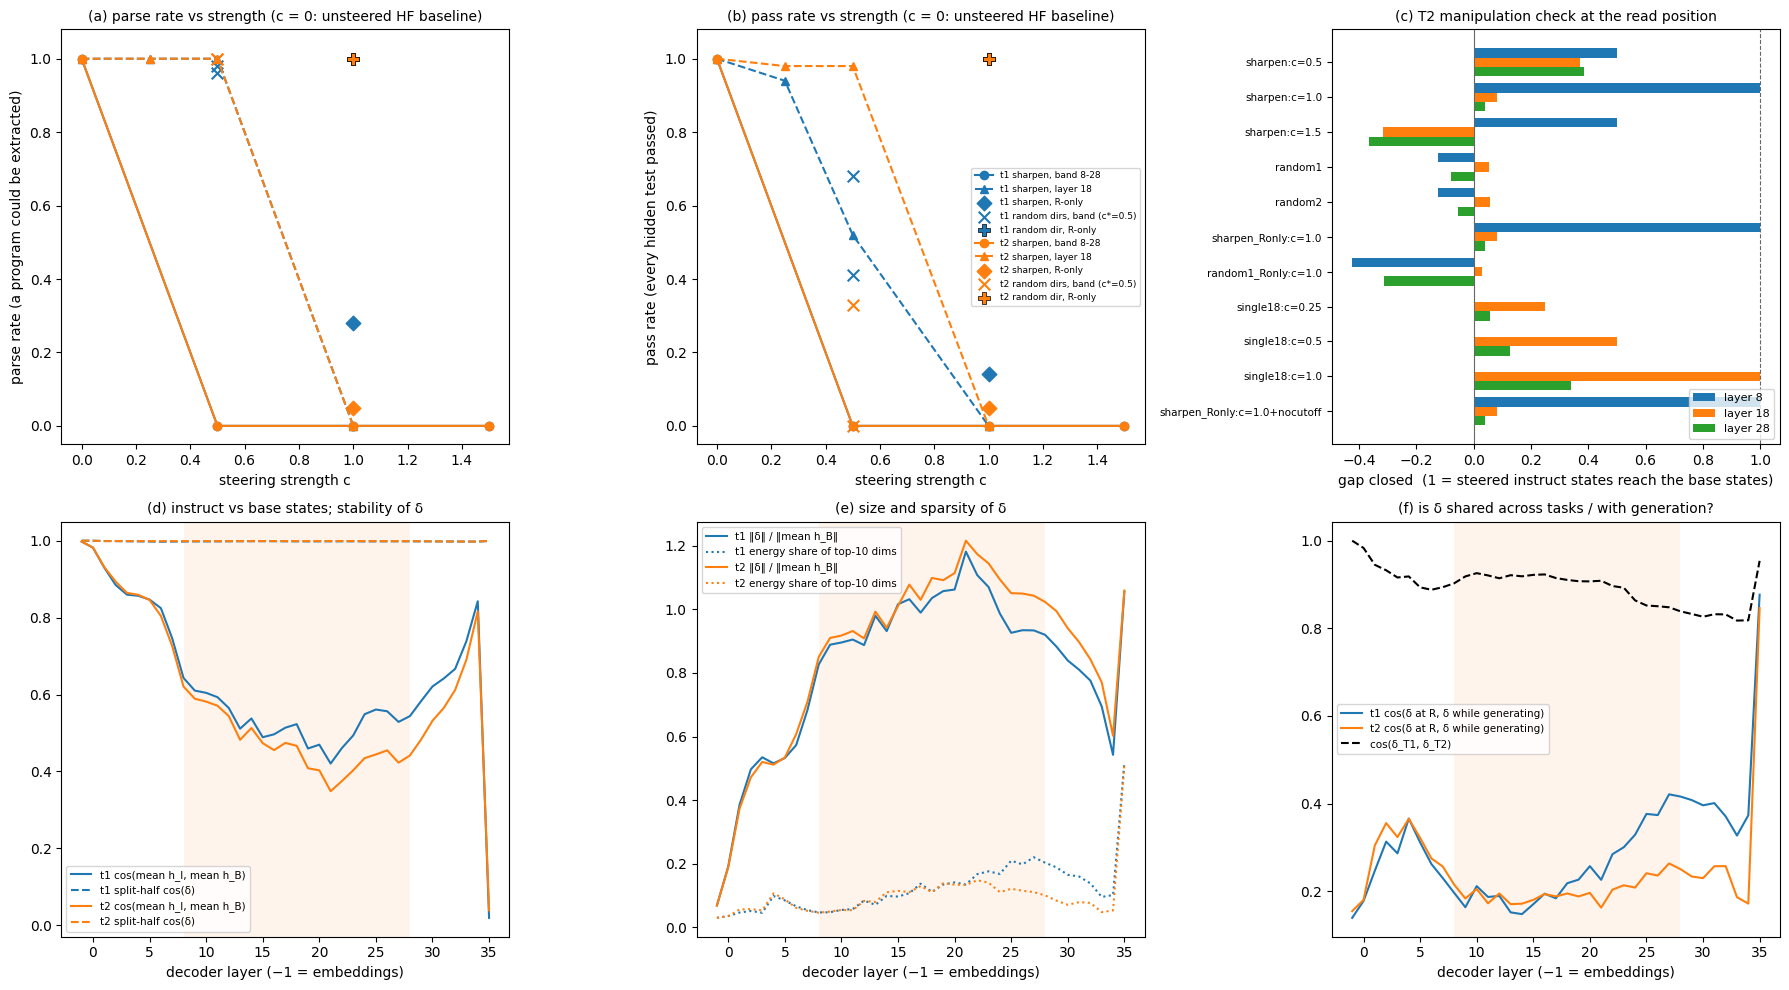

Logit lens at layer 28: tokens whose logit rises / falls most when δ is subtracted from the mean instruct state
  t1 promoted  : 'def', '\tdef', ' def', 'class', '…\n\n\n\n', '偏离', '什么呢', '."\n\n\n\n', 'lessly', '.”\n\n\n\n'
  t1 suppressed: '```', ' ```', ' here', '(single', ' Here', 'Here', 'はこちら', ' <%=', '.opensource', 'Mine'
  t2 promoted  : '指令', 'Conversation', ' Claude', 'Prompt', '擦', 'CHAT', ' prompt', 'chat', 'pulse', 'conversation'
  t2 suppressed: '```', ' ```', '``', 'éré', ' Liga', ' here', ' <%=', '<Block', '大奖', '[^'
knob verdicts: {'t1': 'DESTRUCTIVE', 't2': 'DESTRUCTIVE'} | single-layer family: {'t1': 'NO_EFFECT_WITHIN_BARS', 't2': 'NO_EFFECT_WITHIN_BARS'}


In [19]:
st = meta["steering"]
man = meta["manipulation_gap_closed"]
sdir = meta["sharpening_direction"]
band = sdir["band_layers"]

fig, axes = plt.subplots(2, 3, figsize=(18, 10))


def arm_rate(task: str, name: str, metric: str) -> float:
    a = st[task]["S0"] if name == "S0" else st[task]["arms"].get(name)
    if not a:
        return np.nan
    return a["pass_rate"][0] if metric == "pass_rate" else a["parse_rate"]


FAMILIES = [("band 8-28", ["S0", "steer:sharpen:c=0.5", "steer:sharpen:c=1.0", "steer:sharpen:c=1.5"], [0, 0.5, 1.0, 1.5], "-", "o"),
            ("layer 18", ["S0", "steer:single18:c=0.25", "steer:single18:c=0.5", "steer:single18:c=1.0"], [0, 0.25, 0.5, 1.0], "--", "^")]
# (a, b) parse / pass rate against the steering strength c
for j, (metric, ylab) in enumerate((("parse_rate", "parse rate (a program could be extracted)"),
                                    ("pass_rate", "pass rate (every hidden test passed)"))):
    ax = axes[0, j]
    for task in ("t1", "t2"):
        col = TASK_COLOR[task]
        for fam, names, cvals, ls, mk in FAMILIES:
            ax.plot(cvals, [arm_rate(task, n, metric) for n in names], ls=ls, marker=mk, color=col,
                    label=f"{task} sharpen, {fam}")
        ax.scatter([1.0], [arm_rate(task, "steer:sharpen_Ronly:c=1.0", metric)], marker="D", s=55, color=col,
                   label=f"{task} sharpen, R-only")
        cstar = st[task]["c_star"]
        ax.scatter([cstar, cstar], [arm_rate(task, "steer:random1", metric), arm_rate(task, "steer:random2", metric)],
                   marker="x", s=70, color=col, label=f"{task} random dirs, band (c*={cstar})")
        ax.scatter([1.0], [arm_rate(task, "steer:random1_Ronly:c=1.0", metric)], marker="P", s=70, color=col,
                   edgecolor="k", lw=0.5, label=f"{task} random dir, R-only")
    ax.set_xlabel("steering strength c")
    ax.set_ylabel(ylab)
    ax.set_ylim(-0.05, 1.08)
    ax.set_title(f"({'ab'[j]}) {ylab.split(' (')[0]} vs strength (c = 0: unsteered HF baseline)", fontsize=10)
axes[0, 1].legend(fontsize=6.5, loc="center right")

# (c) manipulation check: gap closed at layers 8 / 18 / 28 (T2)
ax = axes[0, 2]
gap = {**man["manipulation_S"]["t2"], **man["manipulation_R"]["gap_closed"]["t2"], **man["manipulation_X"]["t2"]}
names = list(gap)
for i, L in enumerate(("L8", "L18", "L28")):
    ax.barh(np.arange(len(names)) + (i - 1) * 0.27, [gap[n][L] for n in names], height=0.27, label=f"layer {L[1:]}")
ax.axvline(0, color="0.4", lw=0.8)
ax.axvline(1, color="0.4", lw=0.8, ls="--")
ax.set_yticks(range(len(names)), [n.replace("steer:", "") for n in names], fontsize=7.5)
ax.invert_yaxis()
ax.set_xlabel("gap closed  (1 = steered instruct states reach the base states)")
ax.set_title("(c) T2 manipulation check at the read position", fontsize=10)
ax.legend(fontsize=8, loc="lower right")

# (d, e, f) per-layer geometry of the direction
for task in ("t1", "t2"):
    pl = sdir["tasks"][task]["per_layer"]
    L = [p["decoder_layer"] for p in pl]
    col = TASK_COLOR[task]
    axes[1, 0].plot(L, [p["cos_meanI_meanB"] for p in pl], color=col, label=f"{task} cos(mean h_I, mean h_B)")
    axes[1, 0].plot(L, [p["split_half_cos"] for p in pl], color=col, ls="--", label=f"{task} split-half cos(δ)")
    axes[1, 1].plot(L, [p["rel_norm_delta"] for p in pl], color=col, label=f"{task} ‖δ‖ / ‖mean h_B‖")
    axes[1, 1].plot(L, [p["top10_energy_share"] for p in pl], color=col, ls=":", label=f"{task} energy share of top-10 dims")
    axes[1, 2].plot(L, [p["cos_delta_R_delta_gen"] for p in pl], color=col, label=f"{task} cos(δ at R, δ while generating)")
tg = sdir["task_generality_cos"]
axes[1, 2].plot([g["index"] - 1 for g in tg], [g["cos_delta_t1_t2"] for g in tg], color="k", ls="--",
                label="cos(δ_T1, δ_T2)")
for j, ttl in enumerate(("(d) instruct vs base states; stability of δ", "(e) size and sparsity of δ",
                         "(f) is δ shared across tasks / with generation?")):
    ax = axes[1, j]
    ax.axvspan(band[0], band[-1], color="tab:orange", alpha=0.08, lw=0)
    ax.set_xlabel("decoder layer (−1 = embeddings)")
    ax.set_title(ttl, fontsize=10)
    ax.legend(fontsize=7.5)
plt.tight_layout()
plt.show()

print("Logit lens at layer 28: tokens whose logit rises / falls most when δ is subtracted from the mean instruct state")
for task in ("t1", "t2"):
    ll = sdir["tasks"][task]["logit_lens_L28"]
    print(f"  {task} promoted  : " + ", ".join(repr(t) for t, _ in ll["promoted_by_minus_delta"][:10]))
    print(f"  {task} suppressed: " + ", ".join(repr(t) for t, _ in ll["suppressed_by_minus_delta"][:10]))
print("knob verdicts:", {t: st[t]["knob_verdict"] for t in ("t1", "t2")},
      "| single-layer family:", {t: st[t]["family_verdict|steer:single18"]["verdict"] for t in ("t1", "t2")})

### What does each knob buy, and could the base model predict the post-ban algorithm?

**(a) BUY rows.** For every knob: the change in Hill_cc against its reference, plotted against the pass-rate loss.
* Steering knobs are compared with the unsteered HF run; the ban prompt is compared with instruct chat in vLLM.
* Knobs that leave no correct program have no Hill_cc and sit on the grey strip.
* The T2 ban prompt (outlined) buys the most diversity: +0.83 Hill_cc at 0 pp pass loss.
* The closest steering knob is a *random* read-position-only direction (+0.43 at 0 pp), not the sharpening direction.

**(b) PREDICT rows.** Before phase C (the instruct model under the ban) ran, a forecast of its post-ban algorithm was written
from the base model. Its sha256 was then committed, and phase C refuses to start unless the file still matches.
* The plot shows the log score of each predictor on the realised distribution (higher is better).
* The primary predictor, `base_tf_all`, hit the top-1 algorithm on both tasks and beats the uniform forecast.
* Simpler references, such as the base-chat correct programs, did as well.
* The last lines recompute the hash check.

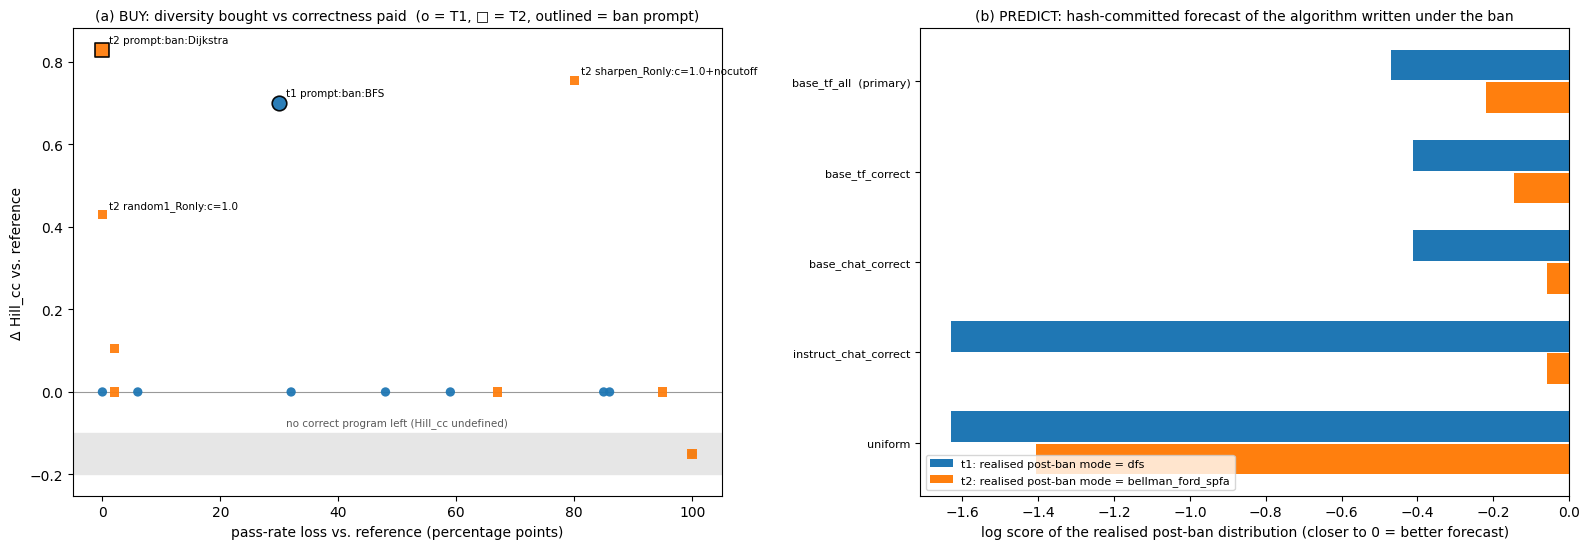

,task,knob,reference,n,pass_rate,hill_cc,delta_hill_cc,pass_loss_pp,efficiency
0,t1,steer:random1,steer:none:c=0 (HF S0),100,0.41,1.000,0.000,59.0,0.000
1,t1,steer:random1_Ronly:c=1.0,steer:none:c=0 (HF S0),100,1.00,1.000,0.000,0.0,0.000
2,t1,steer:random2,steer:none:c=0 (HF S0),100,0.68,1.000,0.000,32.0,0.000
3,t1,steer:sharpen:c=0.5,steer:none:c=0 (HF S0),100,0.00,NaN,NaN,100.0,NaN
4,t1,steer:sharpen:c=1.0,steer:none:c=0 (HF S0),100,0.00,NaN,NaN,100.0,NaN
5,t1,steer:sharpen:c=1.5,steer:none:c=0 (HF S0),100,0.00,NaN,NaN,100.0,NaN
6,t1,steer:sharpen_Ronly:c=1.0,steer:none:c=0 (HF S0),100,0.14,1.000,0.000,86.0,0.000
7,t1,steer:sharpen_Ronly:c=1.0+nocutoff,steer:none:c=0 (HF S0),20,0.15,1.000,0.000,85.0,0.000
8,t1,steer:single18:c=0.25,steer:none:c=0 (HF S0),50,0.94,1.000,0.000,6.0,0.000
9,t1,steer:single18:c=0.5,steer:none:c=0 (HF S0),50,0.52,1.000,0.000,48.0,0.000


,task,event,predictor,primary,top1,realised_mode,top1_hit,log_score,js_to_realised,hash_match
0,t1,t1 ban:BFS,base_chat_correct,False,dfs,dfs,True,-0.412,0.032,True
1,t1,t1 ban:BFS,base_tf_all,True,dfs,dfs,True,-0.470,0.066,True
2,t1,t1 ban:BFS,base_tf_correct,False,dfs,dfs,True,-0.412,0.032,True
3,t1,t1 ban:BFS,instruct_chat_correct,False,dfs,dfs,True,-1.630,0.352,True
4,t1,t1 ban:BFS,uniform,False,dfs,dfs,True,-1.630,0.352,True
5,t2,t2 ban:Dijkstra,base_chat_correct,False,bellman_ford_spfa,bellman_ford_spfa,True,-0.058,0.020,True
6,t2,t2 ban:Dijkstra,base_tf_all,True,bellman_ford_spfa,bellman_ford_spfa,True,-0.220,0.074,True
7,t2,t2 ban:Dijkstra,base_tf_correct,False,bellman_ford_spfa,bellman_ford_spfa,True,-0.144,0.049,True
8,t2,t2 ban:Dijkstra,instruct_chat_correct,False,bellman_ford_spfa,bellman_ford_spfa,True,-0.058,0.020,True
9,t2,t2 ban:Dijkstra,uniform,False,bellman_ford_spfa,bellman_ford_spfa,True,-1.406,0.384,True


forecast sha256 recomputed by assemble(): 94854c80011087e08ae40c998d493605e39e4b6b2b6730a9d635969b539d4d47
sha256 committed before phase C ran     : 94854c80011087e08ae40c998d493605e39e4b6b2b6730a9d635969b539d4d47
-> match: True  (commit 908b4ee08e37; tampered-file guard test: refused: PHASE C REFUSED: prediction file does not match any committed hash)


In [20]:
buy = pd.DataFrame(meta["rows"]["BUY"])
pred = pd.DataFrame(meta["rows"]["PREDICT"])
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(16, 5.6))

# (a) BUY: diversity gained vs pass rate lost, per knob (circles T1, squares T2)
NO_HILL = -0.15
for task, mk in (("t1", "o"), ("t2", "s")):
    for _, r in buy[buy.task == task].iterrows():
        dh = r["delta_hill_cc"]
        ok = dh is not None and not (isinstance(dh, float) and math.isnan(dh))
        is_prompt = r["knob"].startswith("prompt:")
        y = dh if ok else NO_HILL
        ax1.scatter(r["pass_loss_pp"], y, marker=mk, s=110 if is_prompt else 45, color=TASK_COLOR[task],
                    edgecolor="k" if is_prompt else "none", lw=1.2, alpha=0.95 if ok else 0.45, zorder=3)
        if is_prompt or (ok and dh > 0.3):
            ax1.annotate(f"{task} {r['knob'].replace('steer:', '')}", (r["pass_loss_pp"], y), fontsize=7.5,
                         xytext=(5, 5), textcoords="offset points")
ax1.axhline(0, color="0.6", lw=0.8)
ax1.axhspan(NO_HILL - 0.05, NO_HILL + 0.05, color="0.9", zorder=0)
ax1.text(50, NO_HILL + 0.07, "no correct program left (Hill_cc undefined)", fontsize=7.5, ha="center", color="0.35")
ax1.set_xlabel("pass-rate loss vs. reference (percentage points)")
ax1.set_ylabel("Δ Hill_cc vs. reference")
ax1.set_title("(a) BUY: diversity bought vs correctness paid  (o = T1, □ = T2, outlined = ban prompt)", fontsize=10)

# (b) PREDICT: log score of each forecast on the realised post-ban distribution
order = ["base_tf_all", "base_tf_correct", "base_chat_correct", "instruct_chat_correct", "uniform"]
pv = pred.pivot_table(index="predictor", columns="task", values="log_score").reindex(order)
yy = np.arange(len(pv))
for dy, task in ((-0.18, "t1"), (0.18, "t2")):
    realised = pred[pred.task == task]["realised_mode"].iloc[0]
    ax2.barh(yy + dy, pv[task], height=0.34, color=TASK_COLOR[task], label=f"{task}: realised post-ban mode = {realised}")
primary = set(pred[pred.primary]["predictor"])
ax2.set_yticks(yy, [p + ("  (primary)" if p in primary else "") for p in pv.index], fontsize=8)
ax2.invert_yaxis()
ax2.axvline(0, color="0.5", lw=0.8)
ax2.set_xlabel("log score of the realised post-ban distribution (closer to 0 = better forecast)")
ax2.set_title("(b) PREDICT: hash-committed forecast of the algorithm written under the ban", fontsize=10)
ax2.legend(fontsize=8, loc="lower left")
plt.tight_layout()
plt.show()

display(buy[["task", "knob", "reference", "n", "pass_rate", "hill_cc", "delta_hill_cc", "pass_loss_pp", "efficiency"]].round(3))
display(pred[["task", "event", "predictor", "primary", "top1", "realised_mode", "top1_hit", "log_score",
              "js_to_realised", "hash_match"]].round(3))

pc = meta["predict_commit"]
committed = json.loads(pc["hash_log"][0])["sha256"]
print(f"forecast sha256 recomputed by assemble(): {pc['sha256_now']}")
print(f"sha256 committed before phase C ran     : {committed}")
print(f"-> match: {pc['sha256_now'] == committed}  (commit {pc['git_commit'][:12]}; tampered-file guard test: "
      f"{pc['guard_test']['tampered']})")

## Takeaways

* **The collapse is (mostly) installed by post-training.** Under identical chat tokens, the instruct weights write one
  algorithm (T1 BFS 200/200, T2 Dijkstra 193/200), while the base weights spread over more (Hill_cc 1.58 / 2.09).
  D_weights is −0.58 [−1.01, −0.15] on T1 and −0.93 [−1.38, −0.46] on T2.
* **T2 meets every pre-registered bar** (`INSTALLED_BY_POST_TRAINING`). **T1 is `MIXED`**: its modal-share gap of 14.0 pp
  misses the 15 pp bar by 1 pp.
* **Post-training concentrated an existing preference rather than inventing one.** The base model's mode in chat format is
  already BFS / Dijkstra.
* **Format matters too.** The chat template concentrates the instruct model on T2 (Hill_cc 1.93 template-free → 1.16 in
  chat), and it switches the base model's T2 mode from Bellman-Ford to Dijkstra.
* **The residual "sharpening direction" is not a diversity knob.** It is a stable, task-general *answer-format* direction.
  Subtracting it over layers 8–28 destroys the output (0/100 parseable). Layer 18 alone, at c = 0.25, leaves the algorithm
  unchanged. Norm-matched random directions keep the answer format but cost correctness.
* **A prompt-level ban buys more diversity than any internal knob:** T2 Hill_cc 1.16 → 1.99 at 0 pp pass loss.
* **The base model's own distribution forecast the substitute** (DFS, Bellman-Ford) before the instruct model was banned.
  Simpler references did as well.

## Going further

* **Full run.** In the artifact folder, `./install.sh --models` then `.venv/bin/python method.py --all` regenerates
  everything (one ≥ 24 GB GPU, ~3.5 h).
* **CPU re-derivation.** `method.py --assemble`, together with `src/analysis.py`, re-derives every number from the published
  rows on CPU.
* **In this notebook:**
  * Lower `MAX_ROWS_PER_ARM` to see how `assemble()` behaves on less input.
  * To assemble all 4140 rows, point `WS` at a full copy of the artifact folder and skip the rebuild cell.